In [1]:
import pandas as pd
import numpy as np

# Reproducibility
np.random.seed(42)

# Number of records
n = 1000

# -----------------------------
# Basic logistics attributes
# -----------------------------

delivery_ids = [f"ADV{str(i).zfill(5)}" for i in range(1, n + 1)]

delivery_dates = pd.date_range(
    start="2026-01-01",
    periods=365,
    freq="D"
)

vehicle_types = ["Bike", "Van", "Truck"]
origins = ["Warehouse A", "Warehouse B", "Warehouse C"]
destination_zones = [
    "Urban",
    "Suburban",
    "Semi-urban",
    "Rural"
]

traffic_levels = ["Low", "Medium", "High"]
weather_conditions = ["Normal", "Rain", "Storm"]

# -----------------------------
# Generate categorical values
# -----------------------------

vehicle = np.random.choice(
    vehicle_types,
    size=n,
    p=[0.38, 0.42, 0.20]
)

origin = np.random.choice(
    origins,
    size=n
)

zone = np.random.choice(
    destination_zones,
    size=n,
    p=[0.35, 0.30, 0.22, 0.13]
)

traffic = np.random.choice(
    traffic_levels,
    size=n,
    p=[0.31, 0.44, 0.25]
)

weather = np.random.choice(
    weather_conditions,
    size=n,
    p=[0.73, 0.20, 0.07]
)

# -----------------------------
# Generate numerical variables
# -----------------------------

distance = np.round(
    np.random.uniform(3, 45, n),
    2
)

package_count = np.random.randint(
    1, 21, n
)

shipment_volume = np.round(
    package_count * np.random.uniform(0.7, 1.5, n),
    2
)

load_weight = np.round(
    package_count * np.random.uniform(2.5, 15, n),
    2
)

# -----------------------------
# Delivery time
# -----------------------------

traffic_effect = {
    "Low": 0,
    "Medium": 12,
    "High": 28
}

weather_effect = {
    "Normal": 0,
    "Rain": 10,
    "Storm": 25
}

vehicle_time_effect = {
    "Bike": -8,
    "Van": 0,
    "Truck": 12
}

delivery_time = (
    45
    + distance * 2.1
    + package_count * 1.2
    + np.array([traffic_effect[x] for x in traffic])
    + np.array([weather_effect[x] for x in weather])
    + np.array([vehicle_time_effect[x] for x in vehicle])
    + np.random.normal(0, 8, n)
)

delivery_time = np.maximum(delivery_time, 20)
delivery_time = np.round(delivery_time, 2)

# -----------------------------
# Fuel cost
# -----------------------------

fuel_rate = {
    "Bike": 3.2,
    "Van": 6.5,
    "Truck": 10.5
}

fuel_cost = (
    distance
    * np.array([fuel_rate[x] for x in vehicle])
    + np.random.normal(0, 12, n)
)

fuel_cost = np.maximum(fuel_cost, 20)
fuel_cost = np.round(fuel_cost, 2)

# -----------------------------
# Delivery cost
# -----------------------------

vehicle_base_cost = {
    "Bike": 70,
    "Van": 120,
    "Truck": 190
}

delivery_cost = (
    np.array([vehicle_base_cost[x] for x in vehicle])
    + distance * 4.2
    + package_count * 3.5
    + fuel_cost * 0.8
    + np.random.normal(0, 20, n)
)

delivery_cost = np.maximum(delivery_cost, 50)
delivery_cost = np.round(delivery_cost, 2)

# -----------------------------
# Vehicle utilization
# -----------------------------

vehicle_capacity = {
    "Bike": 50,
    "Van": 200,
    "Truck": 500
}

vehicle_utilization = (
    load_weight
    / np.array([vehicle_capacity[x] for x in vehicle])
) * 100

vehicle_utilization += np.random.normal(0, 4, n)

vehicle_utilization = np.clip(
    vehicle_utilization,
    10,
    100
)

vehicle_utilization = np.round(
    vehicle_utilization,
    2
)

# -----------------------------
# On-time delivery
# -----------------------------

expected_time = (
    50
    + distance * 1.8
    + package_count * 1.0
)

on_time = np.where(
    delivery_time <= expected_time,
    "Yes",
    "No"
)

# -----------------------------
# Customer rating
# -----------------------------

rating = (
    4.7
    - np.where(on_time == "No", 0.45, 0)
    - np.where(traffic == "High", 0.15, 0)
    - np.where(weather == "Storm", 0.20, 0)
    + np.random.normal(0, 0.15, n)
)

rating = np.clip(
    rating,
    1,
    5
)

rating = np.round(
    rating,
    2
)

# -----------------------------
# Delivery status
# -----------------------------

delivery_status = np.where(
    np.random.random(n) < 0.96,
    "Completed",
    "Cancelled"
)

# -----------------------------
# Create DataFrame
# -----------------------------

logistics_df = pd.DataFrame({
    "Delivery_ID": delivery_ids,
    "Delivery_Date": np.random.choice(delivery_dates, n),
    "Vehicle_Type": vehicle,
    "Origin": origin,
    "Destination_Zone": zone,
    "Distance_KM": distance,
    "Shipment_Volume": shipment_volume,
    "Package_Count": package_count,
    "Load_Weight_KG": load_weight,
    "Traffic_Level": traffic,
    "Weather_Condition": weather,
    "Delivery_Time_Minutes": delivery_time,
    "Delivery_Cost_INR": delivery_cost,
    "Fuel_Cost_INR": fuel_cost,
    "Vehicle_Utilization_Percent": vehicle_utilization,
    "Customer_Rating": rating,
    "On_Time": on_time,
    "Delivery_Status": delivery_status
})

# -----------------------------
# Display basic information
# -----------------------------

print("Dataset created successfully!")
print("--------------------------------")
print("Number of records:", logistics_df.shape[0])
print("Number of columns:", logistics_df.shape[1])

print("\nColumns:")
print(logistics_df.columns.tolist())

print("\nFirst 10 records:")
display(logistics_df.head(10))

Dataset created successfully!
--------------------------------
Number of records: 1000
Number of columns: 18

Columns:
['Delivery_ID', 'Delivery_Date', 'Vehicle_Type', 'Origin', 'Destination_Zone', 'Distance_KM', 'Shipment_Volume', 'Package_Count', 'Load_Weight_KG', 'Traffic_Level', 'Weather_Condition', 'Delivery_Time_Minutes', 'Delivery_Cost_INR', 'Fuel_Cost_INR', 'Vehicle_Utilization_Percent', 'Customer_Rating', 'On_Time', 'Delivery_Status']

First 10 records:


,Delivery_ID,Delivery_Date,Vehicle_Type,Origin,Destination_Zone,Distance_KM,Shipment_Volume,Package_Count,Load_Weight_KG,Traffic_Level,Weather_Condition,Delivery_Time_Minutes,Delivery_Cost_INR,Fuel_Cost_INR,Vehicle_Utilization_Percent,Customer_Rating,On_Time,Delivery_Status
0,ADV00001,2026-05-22,Bike,Warehouse C,Rural,37.84,4.36,6,65.77,Medium,Normal,138.67,343.49,120.55,100.00,4.22,No,Completed
1,ADV00002,2026-11-26,Truck,Warehouse B,Semi-urban,32.79,2.20,2,17.43,Low,Normal,129.92,615.29,350.85,10.00,4.45,No,Completed
2,ADV00003,2026-08-10,Van,Warehouse C,Urban,7.43,21.25,18,66.15,Low,Rain,93.98,222.64,29.96,36.01,4.33,No,Completed
3,ADV00004,2026-12-22,Van,Warehouse C,Rural,38.23,1.50,2,12.27,Medium,Normal,142.74,458.42,241.92,10.00,4.42,No,Completed
4,ADV00005,2026-04-21,Bike,Warehouse A,Urban,31.18,15.32,12,177.56,Medium,Normal,132.46,340.12,103.52,100.00,4.61,No,Completed
5,ADV00006,2026-04-14,Bike,Warehouse A,Semi-urban,32.28,4.42,5,72.54,Medium,Normal,119.63,293.15,94.15,100.00,4.23,No,Completed
6,ADV00007,2026-01-15,Bike,Warehouse C,Suburban,18.25,24.96,20,130.12,Medium,Normal,116.56,280.40,71.55,100.00,4.28,No,Completed
7,ADV00008,2026-09-27,Truck,Warehouse A,Rural,39.93,10.40,7,104.68,Medium,Normal,154.87,677.25,410.36,21.20,4.20,No,Completed
8,ADV00009,2026-06-08,Van,Warehouse B,Semi-urban,33.47,20.05,16,209.11,Medium,Normal,155.22,485.68,219.27,100.00,4.48,No,Completed
9,ADV00010,2026-06-06,Van,Warehouse B,Semi-urban,7.73,28.13,20,202.74,Low,Normal,91.49,238.59,48.99,100.00,4.64,No,Completed


In [2]:
print("Dataset Shape:", logistics_df.shape)

print("\nMissing Values:")
print(logistics_df.isnull().sum())

print("\nDuplicate Rows:")
print(logistics_df.duplicated().sum())

print("\nData Types:")
print(logistics_df.dtypes)

Dataset Shape: (1000, 18)

Missing Values:
Delivery_ID                    0
Delivery_Date                  0
Vehicle_Type                   0
Origin                         0
Destination_Zone               0
Distance_KM                    0
Shipment_Volume                0
Package_Count                  0
Load_Weight_KG                 0
Traffic_Level                  0
Weather_Condition              0
Delivery_Time_Minutes          0
Delivery_Cost_INR              0
Fuel_Cost_INR                  0
Vehicle_Utilization_Percent    0
Customer_Rating                0
On_Time                        0
Delivery_Status                0
dtype: int64

Duplicate Rows:
0

Data Types:
Delivery_ID                            object
Delivery_Date                  datetime64[ns]
Vehicle_Type                           object
Origin                                 object
Destination_Zone                       object
Distance_KM                           float64
Shipment_Volume                       floa

In [3]:
logistics_df.to_csv(
    "logistics_advanced_analysis_data.csv",
    index=False
)

print("CSV saved successfully!")

CSV saved successfully!


In [4]:
# Basic dataset information

print("DATASET INFORMATION")
print("===================")

print("\nShape:")
print(logistics_df.shape)

print("\nColumn Names:")
print(logistics_df.columns.tolist())

print("\nData Types:")
print(logistics_df.dtypes)

print("\nFirst 10 Records:")
display(logistics_df.head(10))

DATASET INFORMATION

Shape:
(1000, 18)

Column Names:
['Delivery_ID', 'Delivery_Date', 'Vehicle_Type', 'Origin', 'Destination_Zone', 'Distance_KM', 'Shipment_Volume', 'Package_Count', 'Load_Weight_KG', 'Traffic_Level', 'Weather_Condition', 'Delivery_Time_Minutes', 'Delivery_Cost_INR', 'Fuel_Cost_INR', 'Vehicle_Utilization_Percent', 'Customer_Rating', 'On_Time', 'Delivery_Status']

Data Types:
Delivery_ID                            object
Delivery_Date                  datetime64[ns]
Vehicle_Type                           object
Origin                                 object
Destination_Zone                       object
Distance_KM                           float64
Shipment_Volume                       float64
Package_Count                           int64
Load_Weight_KG                        float64
Traffic_Level                          object
Weather_Condition                      object
Delivery_Time_Minutes                 float64
Delivery_Cost_INR                     float64
Fuel_C

,Delivery_ID,Delivery_Date,Vehicle_Type,Origin,Destination_Zone,Distance_KM,Shipment_Volume,Package_Count,Load_Weight_KG,Traffic_Level,Weather_Condition,Delivery_Time_Minutes,Delivery_Cost_INR,Fuel_Cost_INR,Vehicle_Utilization_Percent,Customer_Rating,On_Time,Delivery_Status
0,ADV00001,2026-05-22,Bike,Warehouse C,Rural,37.84,4.36,6,65.77,Medium,Normal,138.67,343.49,120.55,100.00,4.22,No,Completed
1,ADV00002,2026-11-26,Truck,Warehouse B,Semi-urban,32.79,2.20,2,17.43,Low,Normal,129.92,615.29,350.85,10.00,4.45,No,Completed
2,ADV00003,2026-08-10,Van,Warehouse C,Urban,7.43,21.25,18,66.15,Low,Rain,93.98,222.64,29.96,36.01,4.33,No,Completed
3,ADV00004,2026-12-22,Van,Warehouse C,Rural,38.23,1.50,2,12.27,Medium,Normal,142.74,458.42,241.92,10.00,4.42,No,Completed
4,ADV00005,2026-04-21,Bike,Warehouse A,Urban,31.18,15.32,12,177.56,Medium,Normal,132.46,340.12,103.52,100.00,4.61,No,Completed
5,ADV00006,2026-04-14,Bike,Warehouse A,Semi-urban,32.28,4.42,5,72.54,Medium,Normal,119.63,293.15,94.15,100.00,4.23,No,Completed
6,ADV00007,2026-01-15,Bike,Warehouse C,Suburban,18.25,24.96,20,130.12,Medium,Normal,116.56,280.40,71.55,100.00,4.28,No,Completed
7,ADV00008,2026-09-27,Truck,Warehouse A,Rural,39.93,10.40,7,104.68,Medium,Normal,154.87,677.25,410.36,21.20,4.20,No,Completed
8,ADV00009,2026-06-08,Van,Warehouse B,Semi-urban,33.47,20.05,16,209.11,Medium,Normal,155.22,485.68,219.27,100.00,4.48,No,Completed
9,ADV00010,2026-06-06,Van,Warehouse B,Semi-urban,7.73,28.13,20,202.74,Low,Normal,91.49,238.59,48.99,100.00,4.64,No,Completed


In [5]:
# Statistical summary of numerical variables

print("STATISTICAL SUMMARY")
print("===================")

display(logistics_df.describe().round(2))

STATISTICAL SUMMARY


,Delivery_Date,Distance_KM,Shipment_Volume,Package_Count,Load_Weight_KG,Delivery_Time_Minutes,Delivery_Cost_INR,Fuel_Cost_INR,Vehicle_Utilization_Percent,Customer_Rating
count,1000,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,2026-06-27 06:20:09.600000,23.70,11.63,10.56,94.50,122.23,363.87,141.61,56.38,4.26
min,2026-01-01 00:00:00,3.01,0.70,1.00,3.00,36.55,107.08,20.00,10.00,3.59
25%,2026-03-26 18:00:00,13.43,5.81,6.00,36.93,98.15,253.57,66.02,21.56,4.09
50%,2026-06-28 00:00:00,22.95,11.18,11.00,79.03,122.21,339.06,112.88,51.78,4.22
75%,2026-09-26 06:00:00,34.15,16.66,16.00,139.54,145.06,451.04,194.84,100.00,4.38
max,2026-12-31 00:00:00,44.95,29.75,20.00,287.86,205.92,825.12,478.47,100.00,5.00
std,NaN,12.14,6.91,5.76,67.99,30.78,152.75,104.12,35.85,0.24


In [6]:
# Categorical variable distributions

print("VEHICLE TYPE")
print("============")
print(logistics_df["Vehicle_Type"].value_counts())

print("\nDESTINATION ZONE")
print("================")
print(logistics_df["Destination_Zone"].value_counts())

print("\nTRAFFIC LEVEL")
print("=============")
print(logistics_df["Traffic_Level"].value_counts())

print("\nWEATHER CONDITION")
print("=================")
print(logistics_df["Weather_Condition"].value_counts())

print("\nDELIVERY STATUS")
print("================")
print(logistics_df["Delivery_Status"].value_counts())

print("\nON-TIME DELIVERY")
print("=================")
print(logistics_df["On_Time"].value_counts())

VEHICLE TYPE
Vehicle_Type
Bike     401
Van      400
Truck    199
Name: count, dtype: int64

DESTINATION ZONE
Destination_Zone
Urban         344
Suburban      304
Semi-urban    228
Rural         124
Name: count, dtype: int64

TRAFFIC LEVEL
Traffic_Level
Medium    428
Low       325
High      247
Name: count, dtype: int64

WEATHER CONDITION
Weather_Condition
Normal    745
Rain      184
Storm      71
Name: count, dtype: int64

DELIVERY STATUS
Delivery_Status
Completed    959
Cancelled     41
Name: count, dtype: int64

ON-TIME DELIVERY
On_Time
No     872
Yes    128
Name: count, dtype: int64


In [7]:
# Central tendency analysis

numerical_columns = [
    "Distance_KM",
    "Shipment_Volume",
    "Package_Count",
    "Load_Weight_KG",
    "Delivery_Time_Minutes",
    "Delivery_Cost_INR",
    "Fuel_Cost_INR",
    "Vehicle_Utilization_Percent",
    "Customer_Rating"
]

central_tendency = pd.DataFrame({
    "Mean": logistics_df[numerical_columns].mean(),
    "Median": logistics_df[numerical_columns].median(),
    "Std_Dev": logistics_df[numerical_columns].std(),
    "Minimum": logistics_df[numerical_columns].min(),
    "Maximum": logistics_df[numerical_columns].max()
})

display(central_tendency.round(2))

,Mean,Median,Std_Dev,Minimum,Maximum
Distance_KM,23.70,22.95,12.14,3.01,44.95
Shipment_Volume,11.63,11.18,6.91,0.70,29.75
Package_Count,10.56,11.00,5.76,1.00,20.00
Load_Weight_KG,94.50,79.03,67.99,3.00,287.86
Delivery_Time_Minutes,122.23,122.21,30.78,36.55,205.92
Delivery_Cost_INR,363.87,339.06,152.75,107.08,825.12
Fuel_Cost_INR,141.61,112.88,104.12,20.00,478.47
Vehicle_Utilization_Percent,56.38,51.78,35.85,10.00,100.00
Customer_Rating,4.26,4.22,0.24,3.59,5.00


In [8]:
vehicle_analysis = logistics_df.groupby("Vehicle_Type").agg(
    Deliveries=("Delivery_ID", "count"),
    Avg_Distance_KM=("Distance_KM", "mean"),
    Avg_Shipment_Volume=("Shipment_Volume", "mean"),
    Avg_Delivery_Time_Minutes=("Delivery_Time_Minutes", "mean"),
    Avg_Delivery_Cost_INR=("Delivery_Cost_INR", "mean"),
    Avg_Fuel_Cost_INR=("Fuel_Cost_INR", "mean"),
    Avg_Utilization_Percent=("Vehicle_Utilization_Percent", "mean"),
    Avg_Customer_Rating=("Customer_Rating", "mean")
).round(2)

display(vehicle_analysis)

,Deliveries,Avg_Distance_KM,Avg_Shipment_Volume,Avg_Delivery_Time_Minutes,Avg_Delivery_Cost_INR,Avg_Fuel_Cost_INR,Avg_Utilization_Percent,Avg_Customer_Rating
Vehicle_Type,,,,,,,,
Bike,401,24.06,11.59,115.40,269.07,77.07,84.60,4.32
Truck,199,24.13,12.27,136.36,536.42,253.93,20.96,4.19
Van,400,23.13,11.35,122.04,373.06,150.43,45.71,4.23


In [9]:
zone_analysis = logistics_df.groupby("Destination_Zone").agg(
    Deliveries=("Delivery_ID", "count"),
    Avg_Distance_KM=("Distance_KM", "mean"),
    Avg_Shipment_Volume=("Shipment_Volume", "mean"),
    Avg_Delivery_Time_Minutes=("Delivery_Time_Minutes", "mean"),
    Avg_Delivery_Cost_INR=("Delivery_Cost_INR", "mean"),
    Avg_Utilization_Percent=("Vehicle_Utilization_Percent", "mean"),
    Avg_Customer_Rating=("Customer_Rating", "mean")
).round(2)

display(zone_analysis)

,Deliveries,Avg_Distance_KM,Avg_Shipment_Volume,Avg_Delivery_Time_Minutes,Avg_Delivery_Cost_INR,Avg_Utilization_Percent,Avg_Customer_Rating
Destination_Zone,,,,,,,
Rural,124,24.17,12.27,123.04,366.48,58.29,4.26
Semi-urban,228,23.26,11.94,120.94,366.68,55.85,4.26
Suburban,304,23.31,11.55,121.33,355.04,55.75,4.25
Urban,344,24.17,11.26,123.58,368.87,56.59,4.26


In [10]:
# Verify vehicle-level logistics metrics

vehicle_analysis = (
    logistics_df.groupby("Vehicle_Type")
    .agg(
        Deliveries=("Delivery_ID", "count"),
        Avg_Distance_KM=("Distance_KM", "mean"),
        Avg_Shipment_Volume=("Shipment_Volume", "mean"),
        Avg_Delivery_Time_Minutes=("Delivery_Time_Minutes", "mean"),
        Avg_Delivery_Cost_INR=("Delivery_Cost_INR", "mean"),
        Avg_Fuel_Cost_INR=("Fuel_Cost_INR", "mean"),
        Avg_Utilization_Percent=("Vehicle_Utilization_Percent", "mean"),
        Avg_Customer_Rating=("Customer_Rating", "mean")
    )
    .round(2)
    .reset_index()
)

display(vehicle_analysis)

,Vehicle_Type,Deliveries,Avg_Distance_KM,Avg_Shipment_Volume,Avg_Delivery_Time_Minutes,Avg_Delivery_Cost_INR,Avg_Fuel_Cost_INR,Avg_Utilization_Percent,Avg_Customer_Rating
0,Bike,401,24.06,11.59,115.40,269.07,77.07,84.60,4.32
1,Truck,199,24.13,12.27,136.36,536.42,253.93,20.96,4.19
2,Van,400,23.13,11.35,122.04,373.06,150.43,45.71,4.23


In [11]:
zone_analysis = (
    logistics_df.groupby("Destination_Zone")
    .agg(
        Deliveries=("Delivery_ID", "count"),
        Avg_Distance_KM=("Distance_KM", "mean"),
        Avg_Delivery_Time_Minutes=("Delivery_Time_Minutes", "mean"),
        Avg_Delivery_Cost_INR=("Delivery_Cost_INR", "mean"),
        Avg_Utilization_Percent=("Vehicle_Utilization_Percent", "mean"),
        Avg_Customer_Rating=("Customer_Rating", "mean")
    )
    .round(2)
    .reset_index()
)

display(zone_analysis)

,Destination_Zone,Deliveries,Avg_Distance_KM,Avg_Delivery_Time_Minutes,Avg_Delivery_Cost_INR,Avg_Utilization_Percent,Avg_Customer_Rating
0,Rural,124,24.17,123.04,366.48,58.29,4.26
1,Semi-urban,228,23.26,120.94,366.68,55.85,4.26
2,Suburban,304,23.31,121.33,355.04,55.75,4.25
3,Urban,344,24.17,123.58,368.87,56.59,4.26


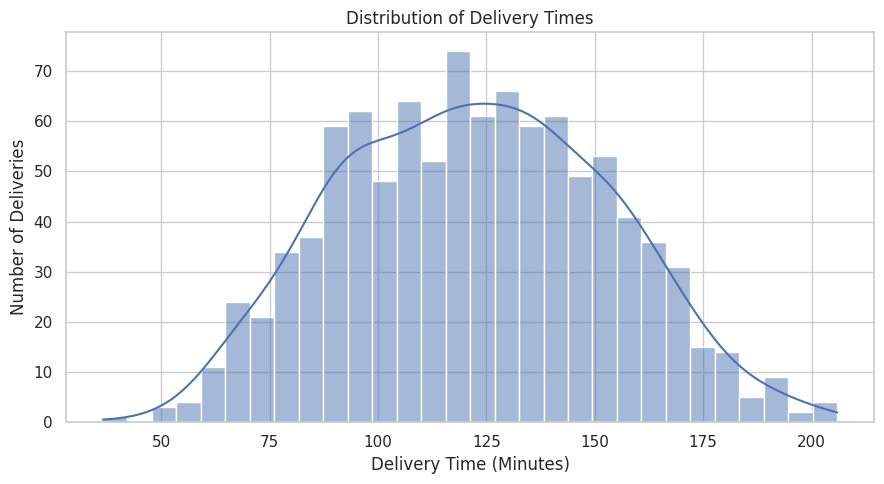

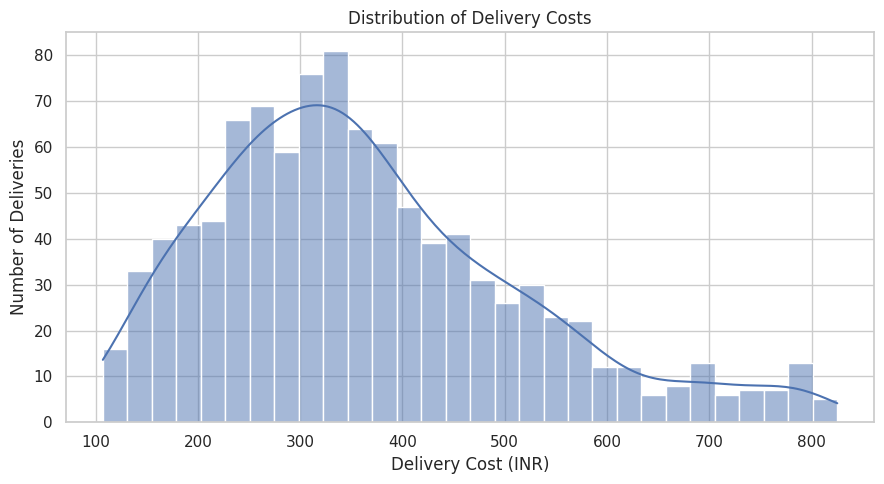

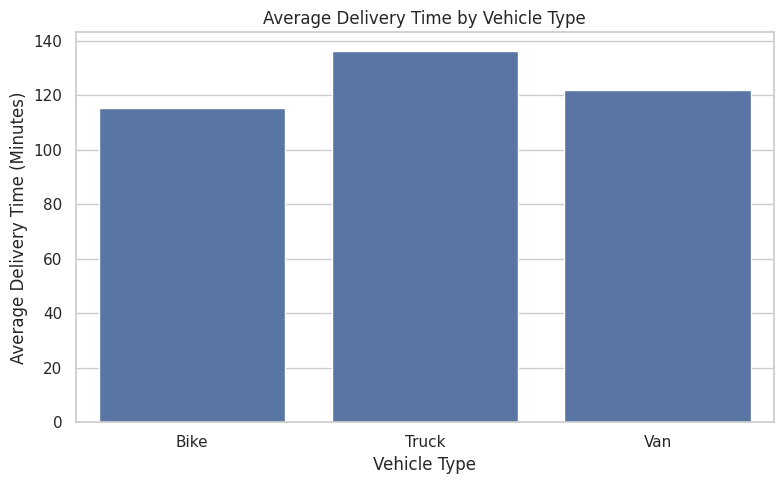

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Distribution of delivery times
plt.figure(figsize=(9, 5))
sns.histplot(
    data=logistics_df,
    x="Delivery_Time_Minutes",
    bins=30,
    kde=True
)
plt.title("Distribution of Delivery Times")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Deliveries")
plt.tight_layout()
plt.savefig("delivery_time_distribution.png", dpi=300)
plt.show()

# 2. Delivery cost distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=logistics_df,
    x="Delivery_Cost_INR",
    bins=30,
    kde=True
)
plt.title("Distribution of Delivery Costs")
plt.xlabel("Delivery Cost (INR)")
plt.ylabel("Number of Deliveries")
plt.tight_layout()
plt.savefig("delivery_cost_distribution.png", dpi=300)
plt.show()

# 3. Average delivery time by vehicle
plt.figure(figsize=(8, 5))
sns.barplot(
    data=logistics_df,
    x="Vehicle_Type",
    y="Delivery_Time_Minutes",
    errorbar=None
)
plt.title("Average Delivery Time by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Delivery Time (Minutes)")
plt.tight_layout()
plt.savefig("delivery_time_by_vehicle.png", dpi=300)
plt.show()

Performance by Traffic Level:


,Traffic_Level,Deliveries,Avg_Delivery_Time,Avg_Delivery_Cost,Avg_Customer_Rating
0,High,247,137.52,359.96,4.08
1,Low,325,107.57,350.08,4.38
2,Medium,428,124.53,376.60,4.27


Performance by Weather Condition:


,Weather_Condition,Deliveries,Avg_Delivery_Time,Avg_Delivery_Cost,Avg_Customer_Rating
0,Normal,745,120.36,368.37,4.29
1,Rain,184,123.61,355.79,4.25
2,Storm,71,138.28,337.59,4.00


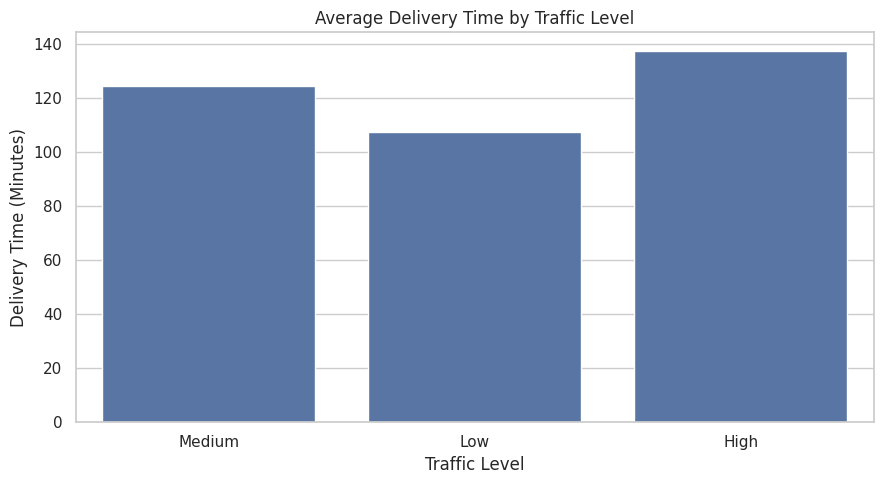

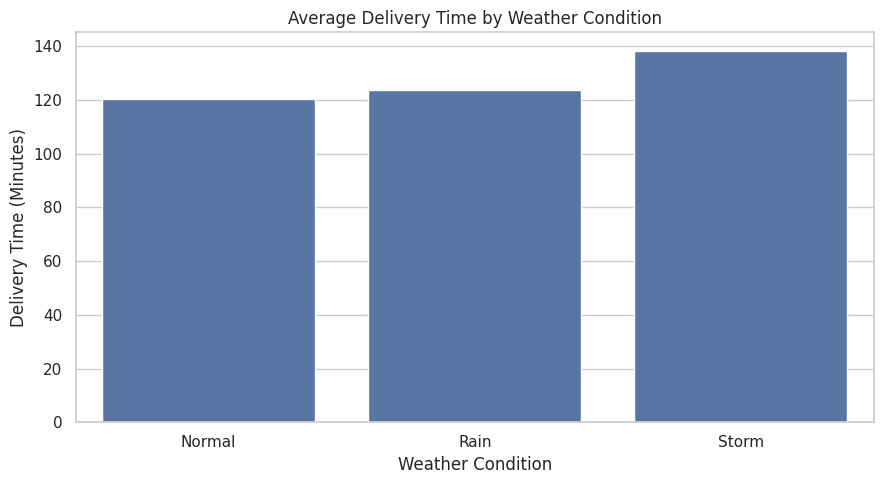

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Average delivery time by traffic level
traffic_analysis = logistics_df.groupby("Traffic_Level").agg(
    Deliveries=("Delivery_ID", "count"),
    Avg_Delivery_Time=("Delivery_Time_Minutes", "mean"),
    Avg_Delivery_Cost=("Delivery_Cost_INR", "mean"),
    Avg_Customer_Rating=("Customer_Rating", "mean")
).round(2).reset_index()

print("Performance by Traffic Level:")
display(traffic_analysis)

# 2. Average delivery time by weather condition
weather_analysis = logistics_df.groupby("Weather_Condition").agg(
    Deliveries=("Delivery_ID", "count"),
    Avg_Delivery_Time=("Delivery_Time_Minutes", "mean"),
    Avg_Delivery_Cost=("Delivery_Cost_INR", "mean"),
    Avg_Customer_Rating=("Customer_Rating", "mean")
).round(2).reset_index()

print("Performance by Weather Condition:")
display(weather_analysis)

# 3. Visualize delivery time by traffic
plt.figure(figsize=(9, 5))
sns.barplot(
    data=logistics_df,
    x="Traffic_Level",
    y="Delivery_Time_Minutes",
    errorbar=None
)
plt.title("Average Delivery Time by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Delivery Time (Minutes)")
plt.tight_layout()
plt.savefig("delivery_time_by_traffic.png", dpi=300)
plt.show()

# 4. Visualize delivery time by weather
plt.figure(figsize=(9, 5))
sns.barplot(
    data=logistics_df,
    x="Weather_Condition",
    y="Delivery_Time_Minutes",
    errorbar=None
)
plt.title("Average Delivery Time by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Delivery Time (Minutes)")
plt.tight_layout()
plt.savefig("delivery_time_by_weather.png", dpi=300)
plt.show()

Correlation Matrix:


,Distance_KM,Shipment_Volume,Package_Count,Load_Weight_KG,Delivery_Time_Minutes,Delivery_Cost_INR,Fuel_Cost_INR,Vehicle_Utilization_Percent,Customer_Rating
Distance_KM,1.00,-0.00,-0.01,-0.01,0.80,0.72,0.70,-0.02,-0.09
Shipment_Volume,-0.00,1.00,0.92,0.71,0.24,0.14,0.04,0.46,-0.07
Package_Count,-0.01,0.92,1.00,0.77,0.26,0.15,0.03,0.49,-0.10
Load_Weight_KG,-0.01,0.71,0.77,1.00,0.20,0.09,-0.00,0.59,-0.09
Delivery_Time_Minutes,0.80,0.24,0.26,0.20,1.00,0.77,0.72,-0.04,-0.41
Delivery_Cost_INR,0.72,0.14,0.15,0.09,0.77,1.00,0.97,-0.37,-0.21
Fuel_Cost_INR,0.70,0.04,0.03,-0.00,0.72,0.97,1.00,-0.43,-0.18
Vehicle_Utilization_Percent,-0.02,0.46,0.49,0.59,-0.04,-0.37,-0.43,1.00,0.11
Customer_Rating,-0.09,-0.07,-0.10,-0.09,-0.41,-0.21,-0.18,0.11,1.00


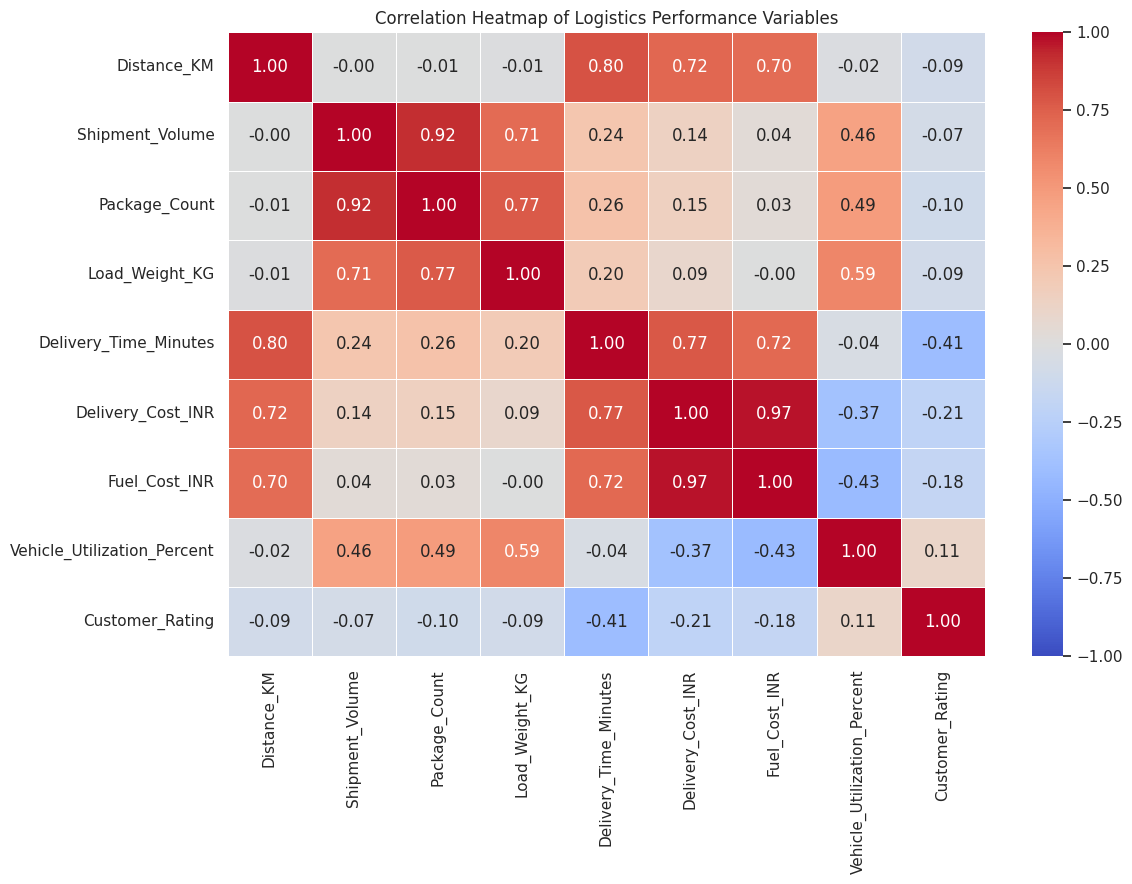

In [14]:

# Select numerical variables for correlation analysis
correlation_columns = [
    "Distance_KM",
    "Shipment_Volume",
    "Package_Count",
    "Load_Weight_KG",
    "Delivery_Time_Minutes",
    "Delivery_Cost_INR",
    "Fuel_Cost_INR",
    "Vehicle_Utilization_Percent",
    "Customer_Rating"
]

correlation_matrix = logistics_df[correlation_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

# Visualize correlations
plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Logistics Performance Variables")
plt.tight_layout()
plt.savefig("logistics_correlation_heatmap.png", dpi=300)
plt.show()


Delivery status distribution:


,Delivery_Status,Deliveries
0,Completed,959
1,Cancelled,41


On-time delivery distribution:


,On_Time,Deliveries
0,No,872
1,Yes,128


On-time performance by vehicle type:


,Vehicle_Type,Total_Deliveries,On_Time_Rate
0,Bike,401,100.0
1,Truck,199,100.0
2,Van,400,100.0


On-time performance by traffic level:


,Traffic_Level,Total_Deliveries,On_Time_Rate
0,High,247,100.0
1,Low,325,100.0
2,Medium,428,100.0


On-time performance by weather:


,Weather_Condition,Total_Deliveries,On_Time_Rate
0,Normal,745,100.0
1,Rain,184,100.0
2,Storm,71,100.0


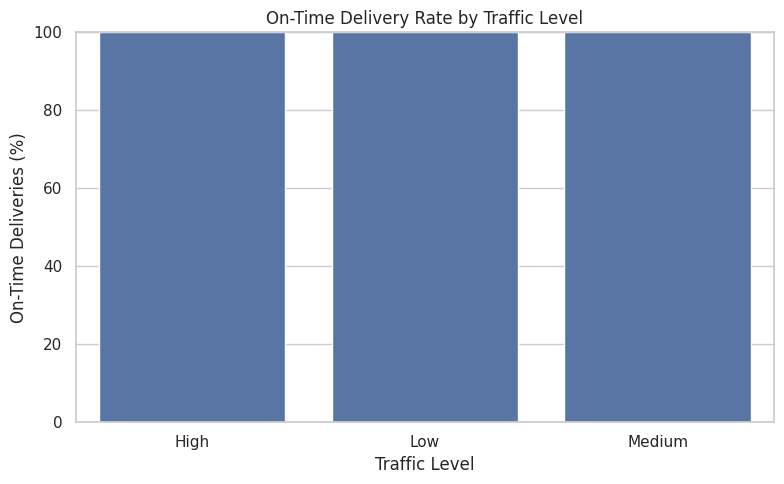

In [15]:

# 1. Overall delivery performance
print("Delivery status distribution:")
display(
    logistics_df["Delivery_Status"]
    .value_counts()
    .rename_axis("Delivery_Status")
    .reset_index(name="Deliveries")
)

print("On-time delivery distribution:")
display(
    logistics_df["On_Time"]
    .value_counts()
    .rename_axis("On_Time")
    .reset_index(name="Deliveries")
)

# 2. On-time rate by vehicle type
vehicle_ontime = logistics_df.groupby("Vehicle_Type").agg(
    Total_Deliveries=("Delivery_ID", "count"),
    On_Time_Rate=("On_Time", lambda x: x.astype(bool).mean() * 100)
).round(2).reset_index()

print("On-time performance by vehicle type:")
display(vehicle_ontime)

# 3. On-time rate by traffic level
traffic_ontime = logistics_df.groupby("Traffic_Level").agg(
    Total_Deliveries=("Delivery_ID", "count"),
    On_Time_Rate=("On_Time", lambda x: x.astype(bool).mean() * 100)
).round(2).reset_index()

print("On-time performance by traffic level:")
display(traffic_ontime)

# 4. On-time rate by weather condition
weather_ontime = logistics_df.groupby("Weather_Condition").agg(
    Total_Deliveries=("Delivery_ID", "count"),
    On_Time_Rate=("On_Time", lambda x: x.astype(bool).mean() * 100)
).round(2).reset_index()

print("On-time performance by weather:")
display(weather_ontime)

# 5. Visualize on-time rate by traffic level
plt.figure(figsize=(8, 5))
sns.barplot(
    data=traffic_ontime,
    x="Traffic_Level",
    y="On_Time_Rate",
    errorbar=None
)
plt.title("On-Time Delivery Rate by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("On-Time Deliveries (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("on_time_rate_by_traffic.png", dpi=300)
plt.show()


In [16]:

# Inspect the actual values and data types
print("On_Time data type:", logistics_df["On_Time"].dtype)
print("\nOn_Time values:")
print(logistics_df["On_Time"].value_counts(dropna=False))

print("\nOn_Time unique values:")
print(logistics_df["On_Time"].unique())

# Correctly calculate the percentage of Yes values
logistics_df["On_Time_Flag"] = (
    logistics_df["On_Time"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("yes")
    .astype(int)
)

print("\nOverall on-time rate:")
print(f"{logistics_df['On_Time_Flag'].mean() * 100:.2f}%")

# Recalculate rates by vehicle, traffic, and weather
for column in ["Vehicle_Type", "Traffic_Level", "Weather_Condition"]:
    result = logistics_df.groupby(column).agg(
        Total_Deliveries=("Delivery_ID", "count"),
        On_Time_Rate=("On_Time_Flag", "mean")
    ).reset_index()

    result["On_Time_Rate"] *= 100

    print(f"\nOn-time performance by {column}:")
    display(result.round(2))


On_Time data type: object

On_Time values:
On_Time
No     872
Yes    128
Name: count, dtype: int64

On_Time unique values:
['No' 'Yes']

Overall on-time rate:
12.80%

On-time performance by Vehicle_Type:


,Vehicle_Type,Total_Deliveries,On_Time_Rate
0,Bike,401,23.44
1,Truck,199,0.50
2,Van,400,8.25



On-time performance by Traffic_Level:


,Traffic_Level,Total_Deliveries,On_Time_Rate
0,High,247,0.00
1,Low,325,31.38
2,Medium,428,6.07



On-time performance by Weather_Condition:


,Weather_Condition,Total_Deliveries,On_Time_Rate
0,Normal,745,16.11
1,Rain,184,4.35
2,Storm,71,0.00


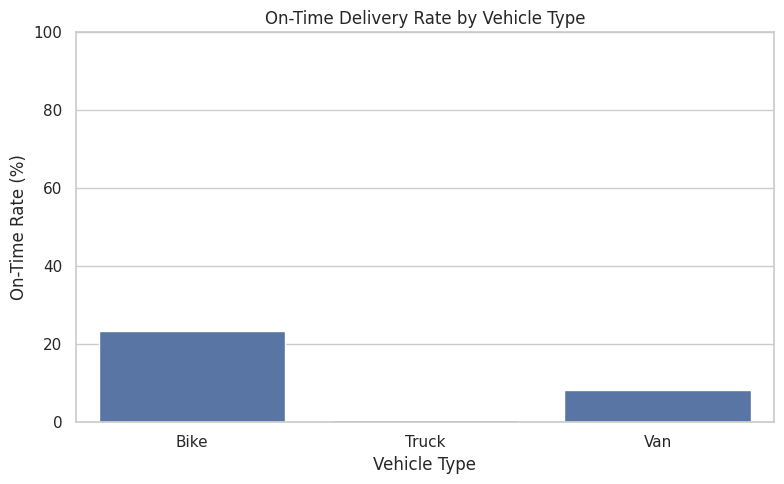

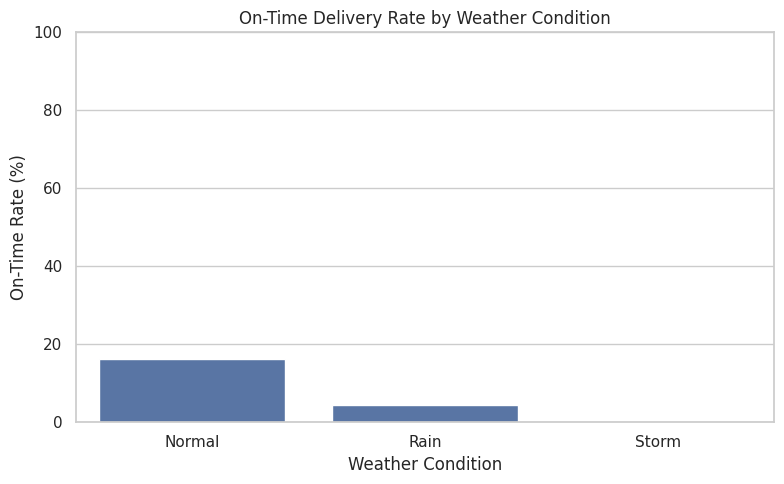

Final on-time performance charts created and saved.


In [17]:

# On-time delivery rate by vehicle type
vehicle_ontime = logistics_df.groupby("Vehicle_Type").agg(
    Total_Deliveries=("Delivery_ID", "count"),
    On_Time_Rate=("On_Time_Flag", "mean")
).reset_index()

vehicle_ontime["On_Time_Rate"] *= 100

plt.figure(figsize=(8, 5))
sns.barplot(
    data=vehicle_ontime,
    x="Vehicle_Type",
    y="On_Time_Rate",
    errorbar=None
)
plt.title("On-Time Delivery Rate by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("On-Time Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("on_time_rate_by_vehicle.png", dpi=300)
plt.show()


# On-time delivery rate by weather
weather_ontime = logistics_df.groupby("Weather_Condition").agg(
    Total_Deliveries=("Delivery_ID", "count"),
    On_Time_Rate=("On_Time_Flag", "mean")
).reset_index()

weather_ontime["On_Time_Rate"] *= 100

plt.figure(figsize=(8, 5))
sns.barplot(
    data=weather_ontime,
    x="Weather_Condition",
    y="On_Time_Rate",
    errorbar=None
)
plt.title("On-Time Delivery Rate by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("On-Time Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("on_time_rate_by_weather.png", dpi=300)
plt.show()

print("Final on-time performance charts created and saved.")


In [18]:

# Export the dataset to a CSV file
csv_filename = "advanced_logistics_dataset.csv"

logistics_df.to_csv(csv_filename, index=False)

print(f"CSV file created: {csv_filename}")
print(f"Number of rows: {len(logistics_df)}")
print(f"Number of columns: {len(logistics_df.columns)}")

# Download the CSV to your computer
from google.colab import files
files.download(csv_filename)


CSV file created: advanced_logistics_dataset.csv
Number of rows: 1000
Number of columns: 19


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>